Mr görüntülerinin görüntülenmesi

   memory  days_to_visit  age at visit
0     0.0              0         65.19
1     0.0            339         66.12
2     0.0            722         67.17
3     0.0           1106         68.22
4     0.0           1456         69.18
MRI boyutları: (176, 256, 256)


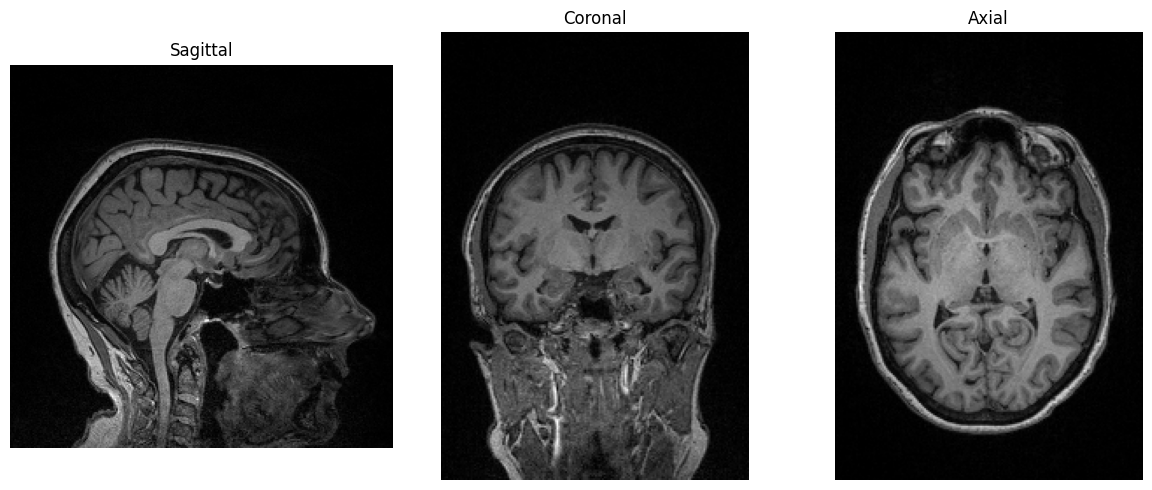

In [2]:
# T1w ağırlıklı mr dosyaları 
import nibabel as nib
import matplotlib.pyplot as plt
import numpy as np
import cv2
import torch
import os
import pandas as pd
file_path = "Inference/sub-OAS30001_sess-d0129_run-01_T1w.nii"

# --- MRI dosyasını yükle ---
img = nib.load(file_path)
data = img.get_fdata()
data_csv = pd.read_csv("Repository/OASIS3_UDSb4_cdr.csv")
cdr_score = data_csv[["memory","days_to_visit","age at visit"]]

print(cdr_score.head())
print("MRI boyutları:", data.shape)

# --- Orta kesitleri seç ---
mid_x = data.shape[0] // 2
mid_y = data.shape[1] // 2
mid_z = data.shape[2] // 2

# --- Üç düzlemde (axial, coronal, sagittal) görüntüle ---
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

axes[0].imshow(np.rot90(data[mid_x, :, :]), cmap="gray")
axes[0].set_title("Sagittal")

axes[1].imshow(np.rot90(data[:, mid_y, :]), cmap="gray")
axes[1].set_title("Coronal")

axes[2].imshow(np.rot90(data[:, :, mid_z]), cmap="gray")
axes[2].set_title("Axial")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


MRI boyutları: (256, 256, 35)


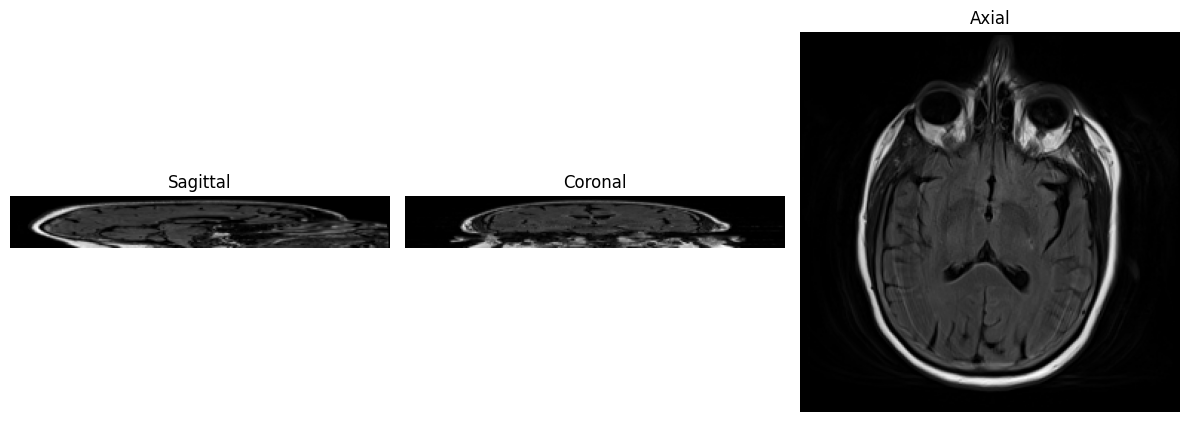

In [3]:
# Flair ağırlıklı mr dosyaları 
file_path1 = "Inference/sub-OAS30001_sess-d4467_FLAIR.nii"

# --- MRI dosyasını yükle ---
img = nib.load(file_path1)
data1 = img.get_fdata()

print("MRI boyutları:", data1.shape)

# --- Orta kesitleri seç ---
mid_x = data1.shape[0] // 2
mid_y = data1.shape[1] // 2
mid_z = data1.shape[2] // 2

# --- Üç düzlemde (axial, coronal, sagittal) görüntüle ---
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

axes[0].imshow(np.rot90(data1[mid_x, :, :]), cmap="gray")
axes[0].set_title("Sagittal")

axes[1].imshow(np.rot90(data1[:, mid_y, :]), cmap="gray")
axes[1].set_title("Coronal")

axes[2].imshow(np.rot90(data1[:, :, mid_z]), cmap="gray")
axes[2].set_title("Axial")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()


In [4]:
data_normal = cv2.normalize(data, None, 0, 255, cv2.NORM_MINMAX)
data_normal = data_normal.astype(np.uint8)

h, w = 256, 256
filename = "mri_sagittal.mp4"
codec = cv2.VideoWriter_fourcc(*"mp4v")

frameRate = 30
out = cv2.VideoWriter(filename,codec,frameRate,(w,h), isColor=False)

# Sagital
for i in range(data_normal.shape[0]):
    frame = np.rot90(data_normal[i, :, :])  
    frame = cv2.resize(frame, (256, 256))  
    
    cv2.imshow("Sagittal MRI", frame)
    # out.write(frame)

    if cv2.waitKey(30) & 0xFF == ord("q"):
        break
out.release()
cv2.destroyAllWindows()


In [5]:
data.shape

(176, 256, 256)

In [6]:
 
def prepare_mri_for_model(data, target_shape=(128, 128, 128)):

    print(f"Orijinal MRI boyutları: {data.shape}")

    # --- Normalize et (0-1 arası) ---
    data = (data - np.min(data)) / (np.max(data) - np.min(data) + 1e-8)

    # --- Derinlik (Z ekseni) boyunca yeniden örnekleme ---
    new_slices = np.linspace(0, data.shape[2] - 1, target_shape[2]).astype(int)
    resized_slices = [cv2.resize(data[:, :, i], target_shape[:2]) for i in new_slices]
    data_resized = np.stack(resized_slices, axis=2)

    # --- Tensöre çevir [B=1, C=1, D, H, W] ---
    tensor = torch.from_numpy(data_resized).unsqueeze(0).unsqueeze(0).float()

    print(f"Yeni MRI boyutları (model girişi): {tensor.shape}")
    return tensor


In [7]:
tensor = prepare_mri_for_model(data)

Orijinal MRI boyutları: (176, 256, 256)
Yeni MRI boyutları (model girişi): torch.Size([1, 1, 128, 128, 128])
